# Project 4: Before–After Defect Reduction (QCC Insulation Damage)

Analisis Q1–Q14. Semua tabel dibaca dari `results/` (hasil skrip SQL dan Python). Data adalah simulasi buatan sendiri. Before = Jan–Jun, transisi = Jul (tidak dipakai di uji), after = Agu–Okt 2026.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'
z = R('ztest.csv').set_index('scope')

## Q1. Rate before dan after
Defect rate = jumlah NG insulation damage (ID-01, ID-02, ID-03) dibagi input.

In [2]:
p = R('period.csv'); p

,period,input_qty,ng_all,ng_id,rate_id,rate_all
0,before,36081.0000,1509,1097,0.0304,0.0418
1,transisi,6929.0000,283,187,0.0270,0.0408
2,after,23644.0000,746,505,0.0214,0.0316


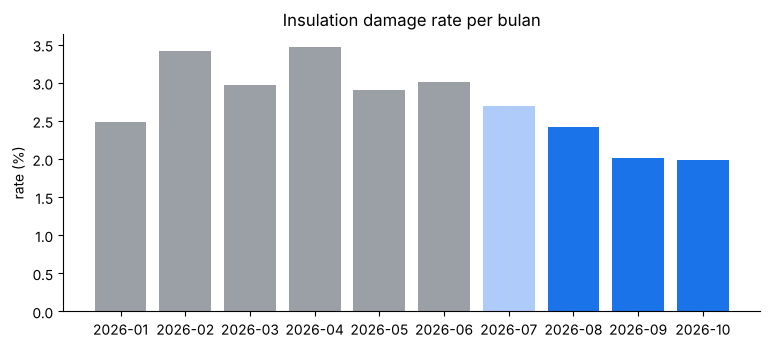

In [3]:
m = R('month.csv'); c = m.period.map({'before': GREY, 'transisi': '#AECBFA', 'after': BLUE})
plt.bar(m.month, m.rate_id * 100, color=c); plt.ylabel('rate (%)'); plt.title('Insulation damage rate per bulan'); plt.show()

## Q2. Jumlah NG vs rate
Volume after lebih tinggi, jadi jumlah NG turun jauh lebih sedikit daripada rate.

In [4]:
R('volume_vs_rate.csv')

,metric,before,after,change
0,Input per bulan,6013.5000,7881.3333,0.3106
1,NG insulation damage per bulan,182.8333,168.3333,-0.0793
2,Insulation damage rate,0.0304,0.0214,-0.2975


## Q3. Per tipe harness

In [5]:
d = R('dim.csv'); d[d.dim == 'harness_type'].pivot(index='val', columns='period', values='rate_id')[['before', 'transisi', 'after']]

period,before,transisi,after
val,,,
A,0.0302,0.0272,0.0219
B,0.0264,0.0248,0.0175
C,0.0379,0.0302,0.0266


In [6]:
z.loc[['Harness tipe A', 'Harness tipe B', 'Harness tipe C'], ['rate_before', 'rate_after', 'rel_drop', 'z', 'p_value', 'ci_low', 'ci_high']]

,rate_before,rate_after,rel_drop,z,p_value,ci_low,ci_high
scope,,,,,,,
Harness tipe A,0.0302,0.0219,0.2739,4.1022,0.0000,0.0044,0.0121
Harness tipe B,0.0264,0.0175,0.3360,4.1778,0.0000,0.0049,0.0129
Harness tipe C,0.0379,0.0266,0.2976,3.3652,0.0008,0.0049,0.0176


## Q4. Uji signifikansi (z-test dua proporsi)
H0: rate before = rate after. α = 0,05, varians gabungan.

In [7]:
z.loc[['Insulation damage (ID-01+02+03)'], ['n_before', 'x_before', 'rate_before', 'n_after', 'x_after', 'rate_after', 'z', 'p_value', 'significant']]

,n_before,x_before,rate_before,n_after,x_after,rate_after,z,p_value,significant
scope,,,,,,,,,
Insulation damage (ID-01+02+03),36081,1097,0.0304,23644,505,0.0214,6.6911,0.0000,True


## Q5. Confidence interval selisih rate (95%, Wald)

In [8]:
z.loc[['Insulation damage (ID-01+02+03)'], ['diff', 'ci_low', 'ci_high', 'rel_drop']]

,diff,ci_low,ci_high,rel_drop
scope,,,,
Insulation damage (ID-01+02+03),0.0090,0.0065,0.0116,0.2975


## Q6. Jumlah sampel minimum
Power 80%, α 0,05. Baris terakhir: penurunan terkecil yang masih terdeteksi dengan data after saat ini.

In [9]:
R('sample_size.csv')

,rel_drop,rate_before,rate_after,n_per_group,months_after,power_actual,kind
0,0.0500,0.0304,0.0289,195360,24.7876,0.1883,skenario
1,0.1000,0.0304,0.0274,47601,6.0396,0.5833,skenario
2,0.1500,0.0304,0.0258,20596,2.6132,0.9098,skenario
3,0.2000,0.0304,0.0243,11265,1.4293,0.9938,skenario
4,0.2700,0.0304,0.0222,5930,0.7523,1.0000,skenario
5,0.1281,0.0304,0.0265,23644,3.0000,0.8000,minimum terdeteksi dengan data after saat ini


## Q7. Stabilitas: p-chart mingguan
Batas 3σ terpisah untuk before dan after. Titik di luar batas ditandai.

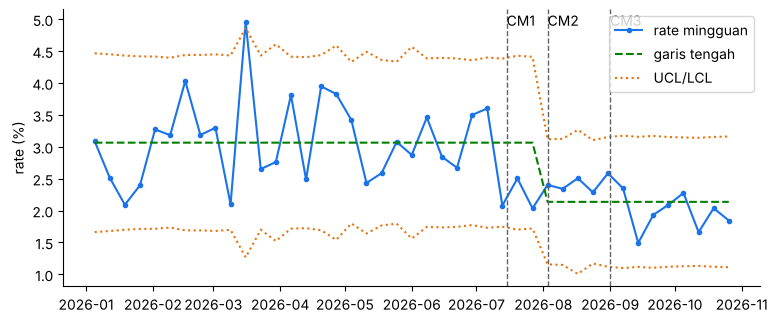

,week_start,period,p,ucl,lcl,out
10,2026-03-16,before,0.0496,0.0486,0.0127,di atas UCL


In [10]:
w = R('pchart.csv'); x = pd.to_datetime(w.week_start)
plt.plot(x, w.p * 100, '-o', ms=3, color=BLUE, label='rate mingguan'); plt.plot(x, w.cl * 100, '--', color='green', label='garis tengah')
plt.plot(x, w.ucl * 100, ':', color=ORANGE, label='UCL/LCL'); plt.plot(x, w.lcl * 100, ':', color=ORANGE)
for r in pd.read_csv(ROOT / 'data' / 'clean' / 'countermeasure_log.csv').itertuples() if (ROOT / 'data' / 'clean').exists() else []:
    plt.axvline(pd.Timestamp(r.start_date), color='#5F6368', ls='--', lw=1); plt.text(pd.Timestamp(r.start_date), plt.ylim()[1] * .95, f'CM{r.cm_id}')
plt.ylabel('rate (%)'); plt.legend(); plt.show()
w[w.out.notna()][['week_start', 'period', 'p', 'ucl', 'lcl', 'out']]

## Q8. Kapan penurunan mulai terlihat
Titik ubah terkuat pada deret mingguan dan efek tiap countermeasure (regresi logistik dengan indikator langkah, disesuaikan operator, shift, tipe).

In [11]:
display(R('changepoint.csv')); display(R('cm_effect.csv')); R('cm_steps.csv')

,changepoint_week,rate_before,rate_after,nearest_cm,offset_days
0,2026-07-13,0.0304,0.0215,1,-2


,cm_id,cm_name,start_date,series,changepoint_week,offset_days,within_7_days,lr_p_value
0,1,Cek isolasi di Wire Cutting & Stripping,2026-07-15,Semua insulation damage,2026-07-13,-2,True,0.0000
1,2,Jig routing + SOP di assembly board,2026-08-03,ID-01 (cara perakitan),2026-07-13,-21,False,0.0007
2,3,Bracket in-house dengan deburring,2026-09-01,ID-02 (tepi bracket),2026-09-07,6,True,0.0071


,series,term,odds_ratio,or_low,or_high,p_value
0,Insulation damage (semua),cm1,0.7081,0.5661,0.8857,0.0025
1,Insulation damage (semua),cm2,1.0936,0.8428,1.4190,0.5007
2,Insulation damage (semua),cm3,0.8160,0.6798,0.9796,0.0291
3,ID-01 Perakitan,cm1,0.7338,0.5464,0.9855,0.0397
4,ID-01 Perakitan,cm2,0.9665,0.6814,1.3710,0.8486
5,ID-01 Perakitan,cm3,0.9065,0.7053,1.1650,0.4431
6,ID-02 Tepi bracket,cm1,0.6835,0.4743,0.9848,0.0412
7,ID-02 Tepi bracket,cm2,1.2226,0.8047,1.8577,0.3463
8,ID-02 Tepi bracket,cm3,0.7119,0.5332,0.9504,0.0212


## Q9. Sumber penyebab

In [12]:
c = R('cause.csv'); c.pivot(index='defect_code', columns='period', values='rate')[['before', 'transisi', 'after']]

period,before,transisi,after
defect_code,,,
ID-01,0.0169,0.0150,0.0115
ID-02,0.0117,0.0102,0.0082
ID-03,0.0019,0.0017,0.0017
OT-01,0.0053,0.0068,0.0045
OT-02,0.0038,0.0036,0.0033
OT-03,0.0024,0.0035,0.0024


In [13]:
z.loc[['ID-01 Perakitan', 'ID-02 Tepi bracket', 'ID-03 Lain-lain'], ['rate_before', 'rate_after', 'diff', 'rel_drop', 'p_value']]

,rate_before,rate_after,diff,rel_drop,p_value
scope,,,,,
ID-01 Perakitan,0.0169,0.0115,0.0054,0.3184,0.0000
ID-02 Tepi bracket,0.0117,0.0082,0.0035,0.3004,0.0000
ID-03 Lain-lain,0.0019,0.0017,0.0002,0.0889,0.6406


## Q10. Apakah operator baru yang makin terampil penyebabnya?
Penurunan juga terjadi pada operator lama, dan efek after tetap besar setelah disesuaikan.

In [14]:
display(z.loc[['Operator lama', 'Operator baru', 'Shift 1', 'Shift 2'], ['rate_before', 'rate_after', 'rel_drop', 'p_value']]); R('model.csv')

,rate_before,rate_after,rel_drop,p_value
scope,,,,
Operator lama,0.0282,0.0218,0.2242,0.0002
Operator baru,0.0356,0.0207,0.4196,0.0000
Shift 1,0.0289,0.0224,0.2237,0.0006
Shift 2,0.0319,0.0203,0.3648,0.0000


,model,term,coef,odds_ratio,or_low,or_high,p_value
0,Tanpa penyesuaian,after,-0.3624,0.6960,0.6256,0.7744,0.0000
1,"Disesuaikan (operator, shift, tipe)",after,-0.3810,0.6832,0.6135,0.7608,0.0000
2,"Disesuaikan (operator, shift, tipe)",op_baru,0.1403,1.1506,1.0338,1.2806,0.0102
3,"Disesuaikan (operator, shift, tipe)",shift2,0.0061,1.0061,0.9082,1.1146,0.9072
4,"Disesuaikan (operator, shift, tipe)",type_B,-0.1583,0.8536,0.7593,0.9597,0.0081
5,"Disesuaikan (operator, shift, tipe)",type_C,0.2322,1.2614,1.1140,1.4282,0.0002


## Q11–Q12. Dampak (estimated / simulated)
Unit terselamatkan = selisih rate × volume per bulan. Biaya per harness adalah asumsi.

In [15]:
R('impact.csv')

,skenario,selisih_rate,volume_per_bulan,unit_per_bulan,unit_per_tahun,biaya_per_unit,hemat_per_tahun,label
0,batas bawah (CI 95%),0.0065,7881.3333,51.1423,613.7074,100000,61370742.4983,estimated/simulated
1,batas bawah (CI 95%),0.0065,7881.3333,51.1423,613.7074,150000,92056113.7474,estimated/simulated
2,batas bawah (CI 95%),0.0065,7881.3333,51.1423,613.7074,250000,153426856.2457,estimated/simulated
3,titik (hasil uji),0.0090,7881.3333,71.2893,855.4711,100000,85547107.8961,estimated/simulated
4,titik (hasil uji),0.0090,7881.3333,71.2893,855.4711,150000,128320661.8442,estimated/simulated
5,titik (hasil uji),0.0090,7881.3333,71.2893,855.4711,250000,213867769.7403,estimated/simulated
6,batas atas (CI 95%),0.0116,7881.3333,91.4362,1097.2347,100000,109723473.2939,estimated/simulated
7,batas atas (CI 95%),0.0116,7881.3333,91.4362,1097.2347,150000,164585209.9409,estimated/simulated
8,batas atas (CI 95%),0.0116,7881.3333,91.4362,1097.2347,250000,274308683.2349,estimated/simulated


## Q13. Kualitas data dan sensitivitas

In [16]:
display(R('cleaning_log.csv')); display(R('data_quality_summary.csv')); R('sensitivity.csv')[['scope', 'rate_before', 'rate_after', 'diff', 'z', 'p_value']]

,rule,table,issue,rows_found,decision,rows_dropped,rows_fixed
0,N1,ng_log,tanggal di luar Jan-Okt 2026,6,dibuang,6,0
1,N2,ng_log,baris ganda (semua kolom sama),20,"dibuang, simpan satu",20,0
2,N3,ng_log,"kode defect salah ketik (ID-1, id-01, ID01, ID...",30,diperbaiki ke format ID-0n,0,30
3,N4,ng_log,shift kosong,10,diisi dari shift operator (dim_operator),0,10
4,P1,production_daily,tanggal di luar Jan-Okt 2026,8,dibuang,8,0
5,P2,production_daily,baris ganda (semua kolom sama),8,"dibuang, simpan satu",8,0
6,P3,production_daily,shift kosong,8,diisi dari shift operator (dim_operator),0,8
7,P4,production_daily,ng_qty lebih besar dari input_qty,10,ng_qty dihitung ulang dari jumlah baris ng_log...,0,10
8,P5,production_daily,ng_qty tidak sama dengan jumlah baris ng_log a...,0,tidak ada sisa,0,0


,table,raw_rows,bad_rows,bad_pct,clean_rows
0,production_daily,1270,34,2.6800,1254
1,ng_log,2564,66,2.5700,2538
2,total,3834,100,2.6100,3792


,scope,rate_before,rate_after,diff,z,p_value
0,A. Data mentah apa adanya (tanpa cleaning),0.0300,0.0207,0.0093,7.0156,0.0000
1,B. Semua baris bermasalah dibuang,0.0301,0.0212,0.0089,6.5602,0.0000
2,C. Cleaning sesuai log (dibuang + diperbaiki),0.0304,0.0214,0.0090,6.6911,0.0000


## Q14. Cek silang SQL, pandas, dan Excel

In [17]:
a, b = R('crosscheck.csv'), R('crosscheck_excel.csv')
print(f'pandas: {(a.status == "PASS").sum()} dari {len(a)} PASS; Excel: {(b.status == "PASS").sum()} dari {len(b)} PASS')

pandas: 348 dari 348 PASS; Excel: 66 dari 66 PASS


## Validasi: lima fakta yang ditanam

In [18]:
R('ground_truth_check.csv')[['fact_no', 'fakta', 'ditemukan', 'hasil']]

,fact_no,fakta,ditemukan,hasil
0,1,"Rate insulation damage turun dari sekitar 3,0%...","before 3.04%, after 2.14%, p = 2.2e-11",Sesuai
1,2,Volume produksi after sekitar 30% lebih tinggi...,volume per bulan +31.1%; NG per bulan -7.9%; r...,Sesuai
2,3,Tiga countermeasure dipasang bertahap; tiap ta...,titik ubah mingguan: CM1 -2 hari; CM2 -21 hari...,Sebagian
3,4,Penurunan terbesar pada ID-01 (perakitan); ID-...,turun ID-01 0.54 poin vs ID-02 0.35 poin; ID-0...,Sesuai
4,5,Sekitar 2-3% data kotor disisipkan (NG > input...,100 baris ditemukan dan ditangani; baris bersi...,Sesuai
